Loading IB (No Scaffolding) from /users/jdtoscan/data/jdtoscan/LLM/Crunch_LLM/Results/PINN_codes/Burgers_Periodic_SinPiX/2026_01_10_1642_human/burgers_pred_complete.npz...
Loading IB (Athena) from /users/jdtoscan/data/jdtoscan/LLM/Crunch_LLM/Results/PINN_codes/Burgers_Periodic_SinPiX/2025_12_04_1621_human_IB/burgers_pred_complete.npz...
Loading KdV (No Scaffolding) from /users/jdtoscan/data/jdtoscan/LLM/Crunch_LLM/Results/PINN_codes/KdV_Mixed_AnalyticalIC/2026_01_09_1804_human/KdV_PINN_MLP_Annealing_RAR_pred_complete.npz...
Loading KdV (Athena) from /users/jdtoscan/data/jdtoscan/LLM/Crunch_LLM/Results/PINN_codes/KdV_Mixed_DerivedIC/2026_01_10_2026_human/Kdv.npz...
  -> Transposing residual for KdV (Athena)


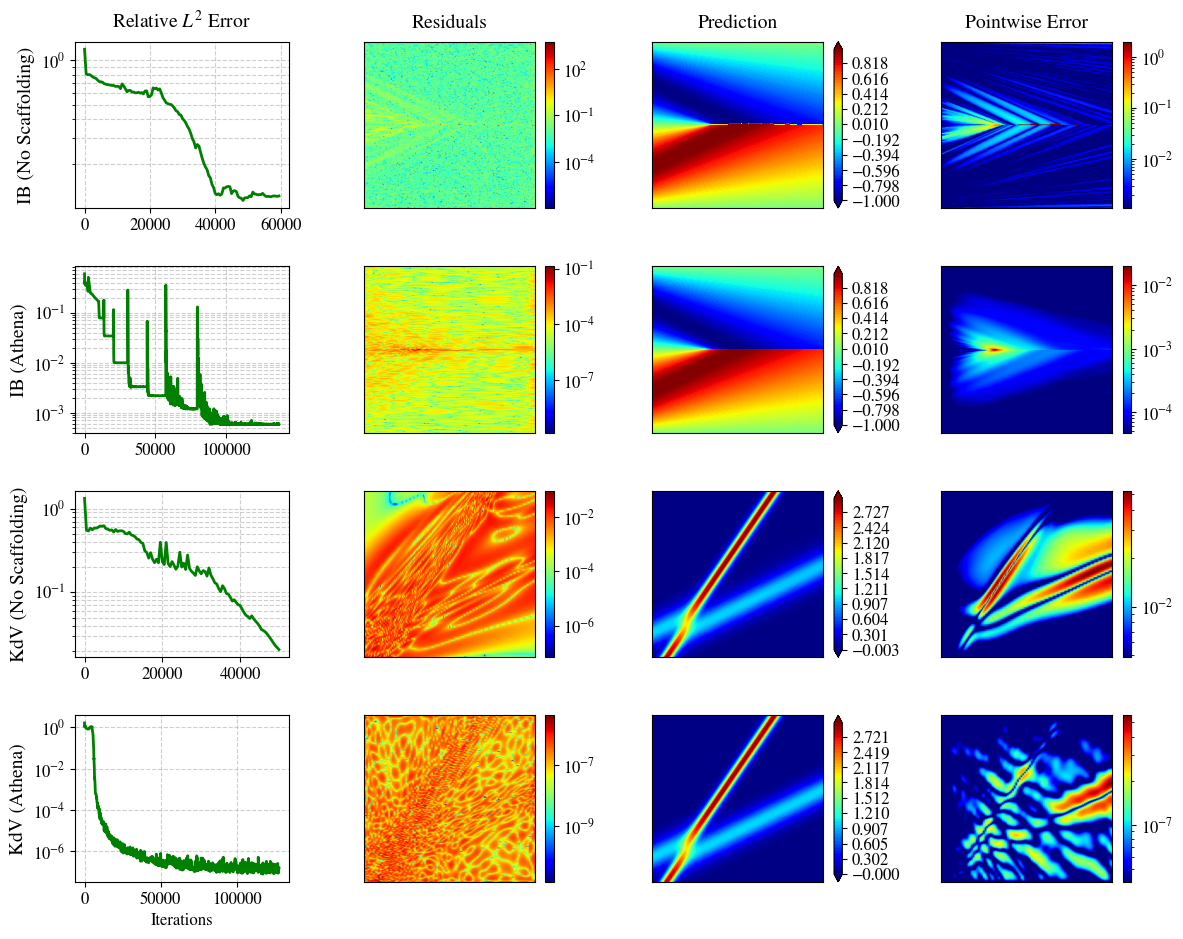


✓ Figure saved as 'comparison_3cases_burgers_kdv.png'

SUMMARY STATISTICS

IB (No Scaffolding):
  Final Relative L2:     1.213962e-01
  Min Relative L2:       1.131651e-01
  Max Pointwise Error:   1.982702e+00
  Mean Pointwise Error:  5.959231e-03
  Max Residual:          5.607587e+03

IB (Athena):
  Final Relative L2:     5.820131e-04
  Min Relative L2:       5.653585e-04
  Max Pointwise Error:   1.990337e-02
  Mean Pointwise Error:  1.027806e-04
  Max Residual:          1.360232e-01

KdV (No Scaffolding):
  Final Relative L2:     2.071453e-02
  Min Relative L2:       2.071453e-02
  Max Pointwise Error:   5.244457e-02
  Mean Pointwise Error:  8.559773e-03
  Max Residual:          9.249715e-02

KdV (Athena):
  Final Relative L2:     1.536840e-07
  Min Relative L2:       7.922833e-08
  Max Pointwise Error:   5.577998e-07
  Mean Pointwise Error:  6.370773e-08
  Max Residual:          4.087168e-06



In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib import colors
import sys

# Set font and style parameters
mpl.rcParams['mathtext.fontset'] = 'stix'
mpl.rcParams['font.family'] = 'STIXGeneral'
mpl.rcParams['font.size'] = 12
mpl.rcParams['figure.dpi'] = 100

# --- Configuration ---
# Dictionary of cases: Label -> File Path
cases_paths = {
    'IB (No Scaffolding)':'/users/jdtoscan/data/jdtoscan/LLM/Crunch_LLM/Results/PINN_codes/Burgers_Periodic_SinPiX/2026_01_10_1642_human/burgers_pred_complete.npz',
    'IB (Athena)': '/users/jdtoscan/data/jdtoscan/LLM/Crunch_LLM/Results/PINN_codes/Burgers_Periodic_SinPiX/2025_12_04_1621_human_IB/burgers_pred_complete.npz',
    'KdV (No Scaffolding)': '/users/jdtoscan/data/jdtoscan/LLM/Crunch_LLM/Results/PINN_codes/KdV_Mixed_AnalyticalIC/2026_01_09_1804_human/KdV_PINN_MLP_Annealing_RAR_pred_complete.npz',
    'KdV (Athena)': '/users/jdtoscan/data/jdtoscan/LLM/Crunch_LLM/Results/PINN_codes/KdV_Mixed_DerivedIC/2026_01_10_2026_human/Kdv.npz'
}

# Define keys to extract (mapping common variations if necessary)
keys_map = {
    'T': ['T', 't_grid'],
    'X': ['X', 'x_grid'],
    'u_pred': ['u_pred', 'pred'],
    'u_exact': ['u_exact', 'Exact', 'exact'],
    'residual': ['pde_residual_grid', 'residual'],
    'iter': ['iter_history', 'all_its'],
    'loss': ['loss_history', 'all_loss'],
    'error': ['error_history', 'all_errors']
}

def load_and_prep_data(path, label):
    print(f"Loading {label} from {path}...")
    try:
        data = np.load(path)
    except Exception as e:
        print(f"Error loading {path}: {e}")
        return None

    extracted = {}
    
    # Helper to find key
    def get_val(possible_keys):
        for k in possible_keys:
            if k in data: return data[k]
        return None

    # Extract basic fields
    extracted['T'] = get_val(keys_map['T'])
    extracted['X'] = get_val(keys_map['X'])
    extracted['u_pred'] = get_val(keys_map['u_pred'])
    extracted['u_exact'] = get_val(keys_map['u_exact'])
    extracted['residual'] = get_val(keys_map['residual'])
    extracted['iter'] = get_val(keys_map['iter'])
    extracted['loss'] = get_val(keys_map['loss'])
    extracted['error'] = get_val(keys_map['error'])

    # Validate essential fields
    if extracted['T'] is None or extracted['u_pred'] is None:
        print(f"CRITICAL: Missing T or u_pred in {label}")
        print(f"Available keys in file: {list(data.keys())}")
        return None

    # --- Shape Correction (Transpose handling) ---
    # Ensure u_pred matches T
    if extracted['u_pred'].shape != extracted['T'].shape:
        if extracted['u_pred'].T.shape == extracted['T'].shape:
            print(f"  -> Transposing u_pred for {label}")
            extracted['u_pred'] = extracted['u_pred'].T
        else:
            print(f"WARNING: Shape mismatch for {label}. T: {extracted['T'].shape}, u_pred: {extracted['u_pred'].shape}")

    # Ensure u_exact matches T
    if extracted['u_exact'] is not None:
        if extracted['u_exact'].shape != extracted['T'].shape:
            if extracted['u_exact'].T.shape == extracted['T'].shape:
                extracted['u_exact'] = extracted['u_exact'].T

    # Ensure residual matches T
    if extracted['residual'] is not None:
        if extracted['residual'].shape != extracted['T'].shape:
             if extracted['residual'].T.shape == extracted['T'].shape:
                print(f"  -> Transposing residual for {label}")
                extracted['residual'] = extracted['residual'].T

    # Calculate Pointwise Error
    if extracted['u_exact'] is not None:
        extracted['pointwise_error'] = np.abs(extracted['u_exact'] - extracted['u_pred'])
    else:
        extracted['pointwise_error'] = np.zeros_like(extracted['u_pred'])

    return extracted

# --- Load Data ---
datasets = {}
for label, path in cases_paths.items():
    datasets[label] = load_and_prep_data(path, label)

# --- Plotting ---
num_cases = len(datasets)
# Adjust figure height based on number of rows (approx 3.5 inches per row)
fig = plt.figure(figsize=(12, 2.5 * num_cases)) 
gs = fig.add_gridspec(num_cases, 4, hspace=0.35, wspace=0.35, 
                      top=0.92, bottom=0.08, left=0.08, right=0.98)

col_labels = ['Relative $L^2$ Error', 'Residuals', 'Prediction', 'Pointwise Error']
error_color = 'green'

for i, (label, data) in enumerate(datasets.items()):
    if data is None: continue

    # 1. Error History
    ax_err = fig.add_subplot(gs[i, 0])
    if data['iter'] is not None and data['error'] is not None:
        ax_err.plot(data['iter'], data['error'], color=error_color, linewidth=2)
        ax_err.set_yscale('log')
        ax_err.grid(True, which="both", ls="--", alpha=0.6)
    
    ax_err.set_ylabel(label, fontsize=14)
    if i == 0: ax_err.set_title(col_labels[0], fontsize=14, pad=10)
    if i == num_cases - 1: ax_err.set_xlabel('Iterations')

    # 2. Residuals
    ax_res = fig.add_subplot(gs[i, 1])
    if data['residual'] is not None:
        res_safe = np.maximum(np.abs(data['residual']), 1e-16)
        res_norm = colors.LogNorm(vmin=res_safe.min(), vmax=res_safe.max())
        mesh_res = ax_res.pcolormesh(data['T'], data['X'], res_safe, cmap='jet', 
                                      norm=res_norm, shading='gouraud')
        fig.colorbar(mesh_res, ax=ax_res)
    
    if i == 0: ax_res.set_title(col_labels[1], fontsize=14, pad=10)
    ax_res.set_xticks([])
    ax_res.set_yticks([])

    # 3. Prediction
    ax_pred = fig.add_subplot(gs[i, 2])
    # Create levels dynamically for each plot
    levels = np.linspace(data['u_pred'].min(), data['u_pred'].max(), 100)
    contour_pred = ax_pred.contourf(data['T'], data['X'], data['u_pred'], cmap='jet', 
                                     levels=levels, extend='both')
    fig.colorbar(contour_pred, ax=ax_pred)
    
    if i == 0: ax_pred.set_title(col_labels[2], fontsize=14, pad=10)
    ax_pred.set_xticks([])
    ax_pred.set_yticks([])

    # 4. Pointwise Error
    ax_perr = fig.add_subplot(gs[i, 3])
    perr_safe = np.maximum(data['pointwise_error'], 1e-16)
    # Use median for vmin to robustly handle zeros
    vmin_val = np.median(perr_safe) if np.median(perr_safe) > 1e-16 else 1e-16
    perr_norm = colors.LogNorm(vmin=vmin_val, vmax=perr_safe.max())
    mesh_perr = ax_perr.pcolormesh(data['T'], data['X'], perr_safe, cmap='jet', 
                                    norm=perr_norm, shading='gouraud')
    fig.colorbar(mesh_perr, ax=ax_perr)
    
    if i == 0: ax_perr.set_title(col_labels[3], fontsize=14, pad=10)
    ax_perr.set_xticks([])
    ax_perr.set_yticks([])

# Save
save_name = 'comparison_3cases_burgers_kdv.png'
plt.savefig(save_name, dpi=300, bbox_inches='tight')
plt.show()
print(f"\n✓ Figure saved as '{save_name}'")

# --- Summary Stats ---
print("\n" + "="*70)
print("SUMMARY STATISTICS")
print("="*70)
for label, data in datasets.items():
    if data is None: continue
    print(f"\n{label}:")
    if data['error'] is not None:
        print(f"  Final Relative L2:     {data['error'][-1]:.6e}")
        print(f"  Min Relative L2:       {data['error'].min():.6e}")
    if 'pointwise_error' in data:
        print(f"  Max Pointwise Error:   {data['pointwise_error'].max():.6e}")
        print(f"  Mean Pointwise Error:  {data['pointwise_error'].mean():.6e}")
    if data['residual'] is not None:
        print(f"  Max Residual:          {np.abs(data['residual']).max():.6e}")
print("\n" + "="*70)